# Uji Validitas dan Reliabilitas Kuesioner (Skala Likert)
**Topik:** Penggunaan AI, Kebiasaan Penggunaan Teknologi Digital, dan Prokrastinasi Akademik  


## Import

In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 80)

##Data


In [3]:
try:
    from google.colab import files
    up = files.upload()
    nama_file = list(up.keys())[0]
except ImportError:
    nama_file = "Blank_Quiz__Responses_.xlsx"
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses).xlsx to Blank Quiz (Responses).xlsx
File terbaca: Blank Quiz (Responses).xlsx


##Membaca data dan memilih kelas


In [4]:
KELAS = "3 TI A"
JUMLAH_KOLOM_DEMOGRAFI = 6
KOLOM_BUKAN_LIKERT = "Durasi (jam)"

df_all = pd.read_excel(nama_file)
print("Respons per kelas:")
print(df_all["Kelas"].value_counts())

df = df_all[df_all["Kelas"].astype(str).str.strip() == KELAS].reset_index(drop=True)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
butir = butir[[c for c in butir.columns if not c.startswith(KOLOM_BUKAN_LIKERT)]]

print()
print("Total respons semua kelas:", len(df_all))
print("Responden kelas", KELAS, ":", len(df))
print("Jumlah butir :", butir.shape[1])
print("Data kosong  :", int(butir.isna().sum().sum()))

Respons per kelas:
Kelas
3 TI E    39
3 TI A    39
3 TI D    38
3 TI C    35
3 TI F    30
Name: count, dtype: int64

Total respons semua kelas: 181
Responden kelas 3 TI A : 39
Jumlah butir : 29
Data kosong  : 0


##Likert menjadi angka

In [7]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")
# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


/tmp/ipykernel_5801/4148410009.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,3,4,5,3,4,5,5,4,3,3,...,2,3,3,3,3,4,4,5,4,5
1,4,5,4,4,2,5,4,3,4,2,...,3,4,2,3,4,1,2,3,4,5
2,4,4,4,4,2,4,5,4,3,2,...,1,4,5,4,5,4,3,4,5,5
3,5,4,2,1,1,5,5,1,2,3,...,1,5,4,4,5,5,1,5,3,1
4,4,4,5,3,4,5,4,5,4,3,...,2,1,1,1,1,4,4,5,1,5


##Mengelompokkan butir per dimensi


In [6]:
RAPIKAN = {
    "Penggunaan AI pada tugas atau projek kuliah": "Penggunaan AI pada Tugas atau Projek Kuliah",
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": "Aspek Psikologis Penggunaan AI",
    "Kebiasaan penggunaan teknologi digital": "Kebiasaan Penggunaan Teknologi Digital",
    "Prokrastinasi akademik.": "Prokrastinasi Akademik",
    "Rsspon emosional": "Respons Emosional",
}

dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?)\[", kolom).group(1).strip()
    dimensi.setdefault(RAPIKAN[nama], []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada Tugas atau Projek Kuliah: 7 butir
Aspek Psikologis Penggunaan AI: 7 butir
Kebiasaan Penggunaan Teknologi Digital: 6 butir
Prokrastinasi Akademik: 4 butir
Respons Emosional: 5 butir


## Uji validitas


In [8]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | t kritis = {t:.3f} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_kor, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "Pernyataan": re.search(r"\[(.*)\]", kolom).group(1).strip(),
            "r hitung": round(r, 3),
            "Corrected r": round(r_kor, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas.drop(columns="Pernyataan")

n = 39 | t kritis = 2.026 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada Tugas atau Projek Kuliah,B1,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada Tugas atau Projek Kuliah,B2,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada Tugas atau Projek Kuliah,B3,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada Tugas atau Projek Kuliah,B4,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada Tugas atau Projek Kuliah,B5,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada Tugas atau Projek Kuliah,B6,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada Tugas atau Projek Kuliah,B7,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis Penggunaan AI,B1,0.538,0.228,0.0004,Valid
8,Aspek Psikologis Penggunaan AI,B2,0.645,0.377,0.0000,Valid
9,Aspek Psikologis Penggunaan AI,B3,0.495,0.213,0.0014,Valid


In [9]:
ringkas = (tabel_validitas.groupby("Dimensi", sort=False)["Keterangan"]
           .value_counts().unstack(fill_value=0))
print("Jumlah butir valid memakai r hitung :", int((tabel_validitas["Keterangan"] == "Valid").sum()),
      "dari", len(tabel_validitas))
print("Jumlah butir dengan corrected r >= 0,30 :", int((tabel_validitas["Corrected r"] >= 0.30).sum()))
ringkas

Jumlah butir valid memakai r hitung : 24 dari 29
Jumlah butir dengan corrected r >= 0,30 : 13


Keterangan,Valid,Tidak valid
Dimensi,,
Penggunaan AI pada Tugas atau Projek Kuliah,5,2
Aspek Psikologis Penggunaan AI,5,2
Kebiasaan Penggunaan Teknologi Digital,5,1
Prokrastinasi Akademik,4,0
Respons Emosional,5,0


## Uji reliabilitas


In [10]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                               "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({"Dimensi": nama, "Butir": f"B{i}",
                                  "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)})

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis Penggunaan AI,7,0.375,Tidak reliabel
2,Kebiasaan Penggunaan Teknologi Digital,6,0.478,Tidak reliabel
3,Prokrastinasi Akademik,4,0.863,Baik
4,Respons Emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada Tugas atau Projek Kuliah,B1,0.275
1,Penggunaan AI pada Tugas atau Projek Kuliah,B2,0.362
2,Penggunaan AI pada Tugas atau Projek Kuliah,B3,0.193
3,Penggunaan AI pada Tugas atau Projek Kuliah,B4,0.171
4,Penggunaan AI pada Tugas atau Projek Kuliah,B5,0.367
5,Penggunaan AI pada Tugas atau Projek Kuliah,B6,0.348
6,Penggunaan AI pada Tugas atau Projek Kuliah,B7,0.513
7,Aspek Psikologis Penggunaan AI,B1,0.299
8,Aspek Psikologis Penggunaan AI,B2,0.200
9,Aspek Psikologis Penggunaan AI,B3,0.312


##Keputusan per butir

In [11]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
alpha_dim = tabel_reliabilitas.set_index("Dimensi")["Cronbach's alpha"]

def keputusan(baris):
    valid = baris["Keterangan"] == "Valid"
    ad = baris["Alpha jika dihapus"]
    if pd.isna(ad):
        return "Valid" if valid else "Tidak valid"
    naik = ad > alpha_dim[baris["Dimensi"]]
    if valid and not naik: return "Valid, pertahankan"
    if valid and naik:     return "Valid, tinjau isi butir"
    if not valid and naik: return "Tidak valid, buang atau revisi"
    return "Tidak valid, tinjau ulang"

gabung["Keputusan"] = gabung.apply(keputusan, axis=1)
gabung.drop(columns="Pernyataan")

,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan,Alpha jika dihapus,Keputusan
0,Penggunaan AI pada Tugas atau Projek Kuliah,B1,0.525,0.277,0.0006,Valid,0.275,"Valid, pertahankan"
1,Penggunaan AI pada Tugas atau Projek Kuliah,B2,0.269,0.105,0.0972,Tidak valid,0.362,"Tidak valid, tinjau ulang"
2,Penggunaan AI pada Tugas atau Projek Kuliah,B3,0.643,0.379,0.0000,Valid,0.193,"Valid, pertahankan"
3,Penggunaan AI pada Tugas atau Projek Kuliah,B4,0.669,0.397,0.0000,Valid,0.171,"Valid, pertahankan"
4,Penggunaan AI pada Tugas atau Projek Kuliah,B5,0.515,0.126,0.0008,Valid,0.367,"Valid, pertahankan"
5,Penggunaan AI pada Tugas atau Projek Kuliah,B6,0.455,0.139,0.0036,Valid,0.348,"Valid, pertahankan"
6,Penggunaan AI pada Tugas atau Projek Kuliah,B7,0.016,-0.247,0.9237,Tidak valid,0.513,"Tidak valid, buang atau revisi"
7,Aspek Psikologis Penggunaan AI,B1,0.538,0.228,0.0004,Valid,0.299,"Valid, pertahankan"
8,Aspek Psikologis Penggunaan AI,B2,0.645,0.377,0.0000,Valid,0.200,"Valid, pertahankan"
9,Aspek Psikologis Penggunaan AI,B3,0.495,0.213,0.0014,Valid,0.312,"Valid, pertahankan"


## Analisis deskriptif per dimensi


In [12]:
deskriptif = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    rata_butir = x.mean(axis=1)
    deskriptif.append({
        "Dimensi": nama, "Jumlah butir": len(daftar),
        "Mean skor total": round(total.mean(), 2), "SD skor total": round(total.std(ddof=1), 3),
        "Mean per butir": round(rata_butir.mean(), 2),
        "Skewness": round(total.skew(), 3), "Kurtosis (excess)": round(total.kurt(), 3),
        "Min": int(total.min()), "Maks": int(total.max()),
    })
tabel_deskriptif = pd.DataFrame(deskriptif)
tabel_deskriptif

,Dimensi,Jumlah butir,Mean skor total,SD skor total,Mean per butir,Skewness,Kurtosis (excess),Min,Maks
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,27.28,3.017,3.90,-0.425,1.612,19,34
1,Aspek Psikologis Penggunaan AI,7,21.92,3.737,3.13,0.248,-0.752,15,30
2,Kebiasaan Penggunaan Teknologi Digital,6,16.69,3.722,2.78,-0.255,-0.212,8,24
3,Prokrastinasi Akademik,4,11.05,4.065,2.76,0.236,-0.553,4,19
4,Respons Emosional,5,19.38,3.322,3.88,-1.524,3.948,7,25


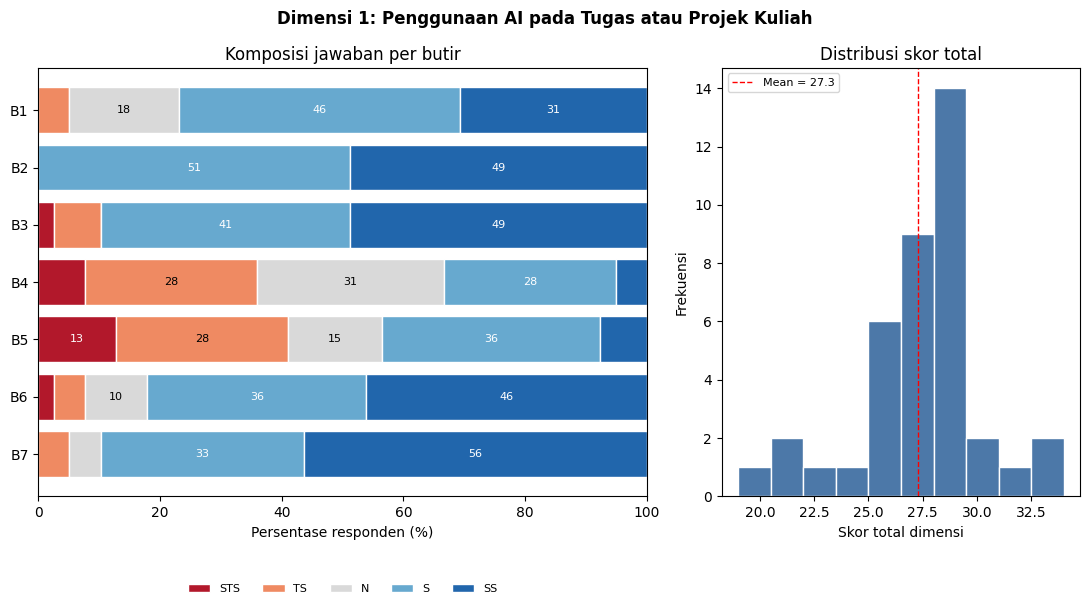

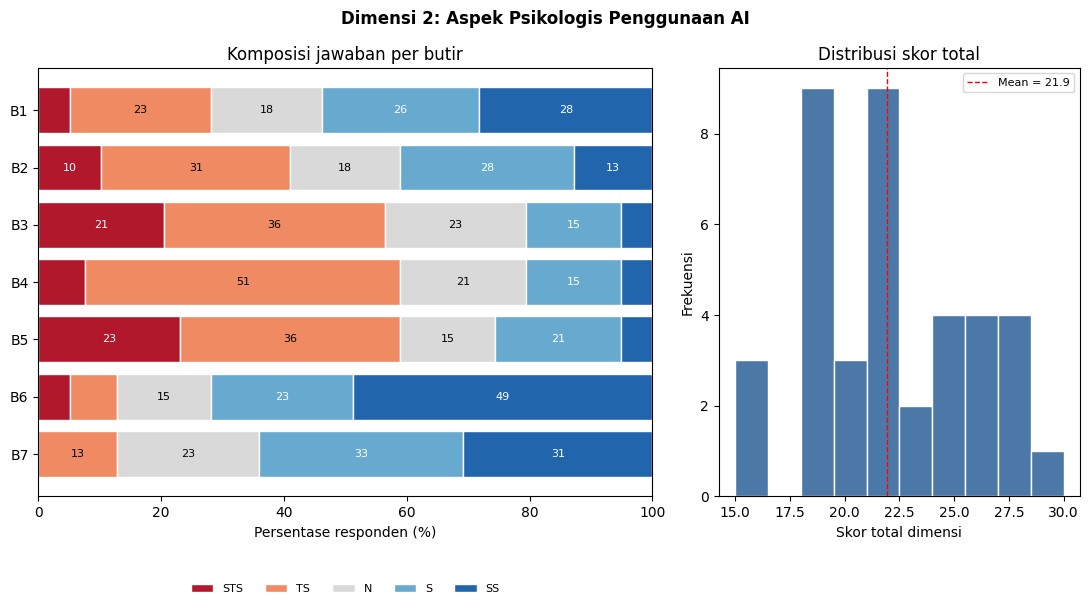

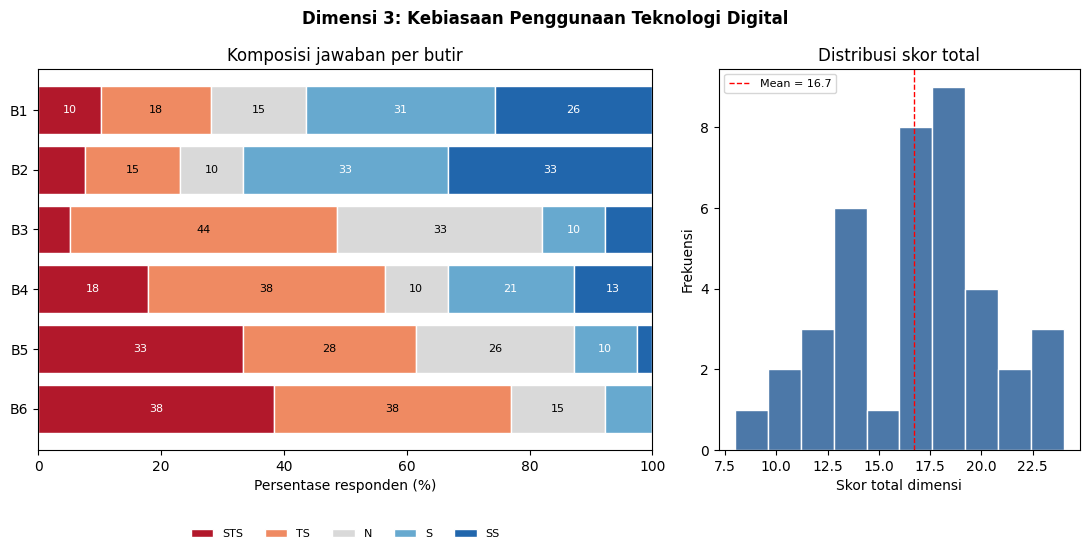

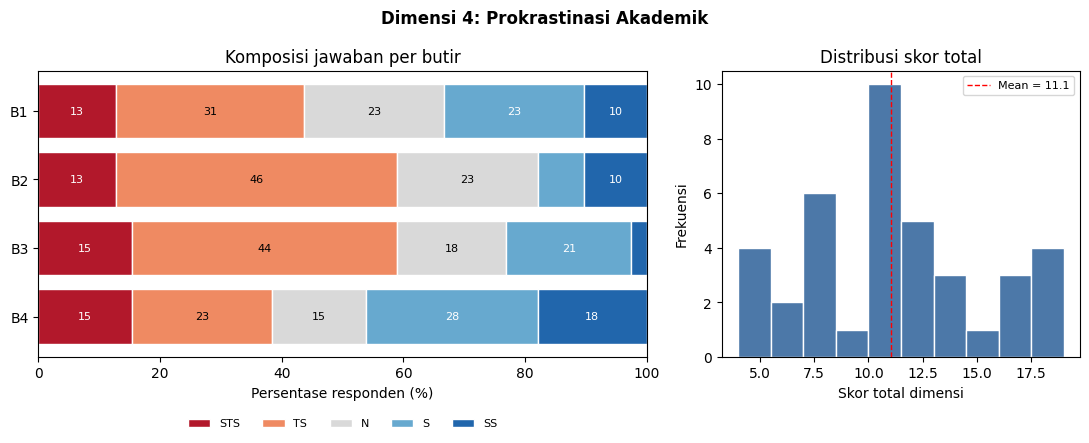

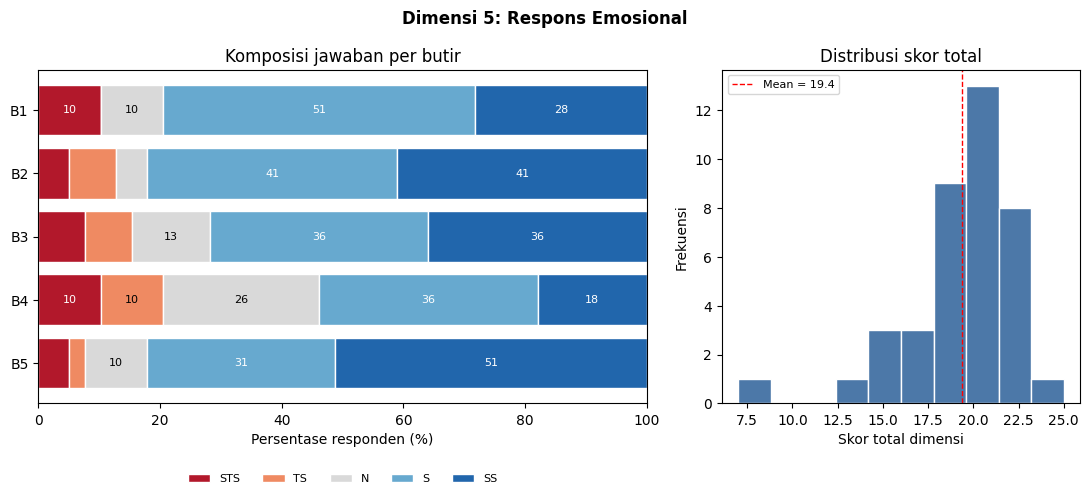

In [13]:
label = ["STS", "TS", "N", "S", "SS"]
warna = ["#b2182b", "#ef8a62", "#d9d9d9", "#67a9cf", "#2166ac"]

for idx, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    pct = pd.DataFrame({lbl: (x == k).mean() * 100 for k, lbl in zip(range(1, 6), label)})
    pct.index = [f"B{i}" for i in range(1, len(daftar) + 1)]

    fig, ax = plt.subplots(1, 2, figsize=(11, 0.55 * len(daftar) + 2.4),
                           gridspec_kw={"width_ratios": [1.7, 1]})
    left = np.zeros(len(pct))
    for lbl, w in zip(label, warna):
        ax[0].barh(pct.index, pct[lbl], left=left, color=w, label=lbl, edgecolor="white")
        for yi, (l0, v) in enumerate(zip(left, pct[lbl])):
            if v >= 8:
                ax[0].text(l0 + v / 2, yi, f"{v:.0f}", ha="center", va="center", fontsize=8,
                           color="white" if lbl in ("STS", "S", "SS") else "black")
        left += pct[lbl].values
    ax[0].invert_yaxis(); ax[0].set_xlim(0, 100)
    ax[0].set_xlabel("Persentase responden (%)")
    ax[0].set_title("Komposisi jawaban per butir")
    ax[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8)

    total = x.sum(axis=1)
    ax[1].hist(total, bins=min(10, total.nunique()), color="#4C78A8", edgecolor="white")
    ax[1].axvline(total.mean(), color="red", ls="--", lw=1, label=f"Mean = {total.mean():.1f}")
    ax[1].set_xlabel("Skor total dimensi"); ax[1].set_ylabel("Frekuensi")
    ax[1].set_title("Distribusi skor total"); ax[1].legend(fontsize=8)

    fig.suptitle(f"Dimensi {idx}: {nama}", fontweight="bold")
    fig.tight_layout()
    fig.savefig(f"grafik_dimensi_{idx}.png", dpi=170)
    plt.show()

## Uji tambahan : membalik skor butir berlawanan arah


In [14]:
balik = {
    "Penggunaan AI pada Tugas atau Projek Kuliah": [6],
    "Aspek Psikologis Penggunaan AI": [5, 6],
}
for nama, idxs in balik.items():
    x = num[dimensi[nama]].copy()
    for i in idxs:
        x.iloc[:, i] = 6 - x.iloc[:, i]
    sebelum = alpha_dim[nama]
    print(f"{nama}: alpha {sebelum:.3f} -> {cronbach_alpha(x):.3f} setelah membalik butir B{[i+1 for i in idxs]}")

Penggunaan AI pada Tugas atau Projek Kuliah: alpha 0.370 -> 0.543 setelah membalik butir B[7]
Aspek Psikologis Penggunaan AI: alpha 0.375 -> 0.674 setelah membalik butir B[6, 7]


## Menyimpan hasil ke Excel

In [16]:
nama_hasil = "hasil_uji_validitas_reliabilitas.xlsx"
with pd.ExcelWriter(nama_hasil) as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)
    tabel_deskriptif.to_excel(w, sheet_name="Deskriptif Dimensi", index=False)
print("Tersimpan:", nama_hasil)

try:
    files.download(nama_hasil)
except NameError:
    pass

Tersimpan: hasil_uji_validitas_reliabilitas.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>